# Data: BRFSS Survey Data in several years [Analyze]

Links: https://www.cdc.gov/brfss/annual_data/annual_*.html (*: 2024, 2023, 2022)

---

In [26]:
import glob
import os
import re

import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import SelectFromModel

from sklearn.linear_model import Ridge, Lasso, LinearRegression, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from tabicl import TabICLClassifier, TabICLRegressor

import shap

# Load

In [27]:
# Constants

n_important_features = 40

n_years = 3

target = "MENTHLTH" # Number of mentally unhealthy days
target_ = "LSATISFY"

In [28]:
df = pd.read_csv(f"data/preprocessed/3-years_39999-samples_68-features_raw.csv")

print(df.shape)

(39999, 70)


In [29]:
df.head()

,DIFFDRES,CELLFON5,_HISPANC,_INCOMG1,DIFFALON,_RFBING6,HHADULT,CHCSCNC1,_AIDTST4,_MICHD,...,_TOTINDA,USENOW3,HAVARTH4,_IMPRACE,_RFHLTH,LCSCTSC1,CHCKDNY2,BMI,MENTHLTH,LSATISFY
0,2.0,1.0,2.0,9.0,2.0,1.0,2.0,1.0,1.0,2.0,...,1.0,3.0,1.0,1.0,1.0,1.0,2.0,27.46,5.0,2.0
1,2.0,1.0,2.0,9.0,2.0,1.0,2.0,2.0,2.0,2.0,...,1.0,3.0,2.0,1.0,1.0,2.0,2.0,20.22,0.0,1.0
2,2.0,1.0,2.0,5.0,2.0,1.0,3.0,2.0,2.0,2.0,...,1.0,3.0,2.0,1.0,1.0,2.0,1.0,27.46,0.0,1.0
3,1.0,1.0,2.0,5.0,1.0,1.0,2.0,2.0,2.0,1.0,...,2.0,3.0,1.0,1.0,2.0,1.0,2.0,33.67,0.0,1.0
4,2.0,1.0,1.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,...,1.0,3.0,2.0,5.0,1.0,2.0,2.0,23.91,5.0,1.0


In [30]:
X = df.drop([target, target_], axis = 1)
print(X.shape)

y = df[target]
print(y.shape)

y_ = df[target_]
print(y_.shape)

(39999, 68)
(39999,)
(39999,)


In [31]:
m, n = X.shape

print("m:", m)
print("n:", n)

m: 39999
n: 68


In [32]:
feature_names = list(df.columns)
print(feature_names)

print(df.shape)

m, n = df.shape

print(f"m: {m}")
print(f"n: {n}")


#    BRFSS uses special codes instead of leaving fields blank:
#    7/77/777/7777 = Don't know / Not sure
#    8/88/888/8888 = Refused
#    9/99/999/9999 = Missing / Unknown
# ============================================================
# Standard missing codes (will apply to all OTHER columns)
standard_missing_codes = [
    7, 8, 9,
    77, 88, 99,
    777, 888, 999,
    7777, 8888, 9999
]

# For special variables, only remove extended missing codes
# (keep 7, 8, 9, and 88 as valid)
special_missing_codes = [
    77, 99,
    777, 999,
    7777, 9999
]

# Group 1: Health days (88 = 0 days, 7/8/9 = valid days)
health_days_vars = ['PHYSHLTH', 'MENTHLTH', 'POORHLTH']

# Group 2: Counts (7/8/9 = valid counts)
count_vars = [
    'NUMADULT', 'HHADULT', 'NUMHHOL4', 'NUMPHON4', 
    'CHILDREN', '_CHLDCNT'
]

# Group 3: Age values (7/8/9 = valid ages)
age_vars = ['DIABAGE4', 'CNCRAGE', '_AGE80']

# Group 4: Drinks (7/8/9 = valid number of drinks)
drink_vars = ['AVEDRNK4', 'MAXDRNKS', 'DRNK3GE5']

# Group 5: Cigarettes (7/8/9 = valid counts)
smoke_vars = ['LCSNUMCG', 'LCSNUMC_', '_PACKDAY']

# Group 6: Income levels (7/8/9 = valid brackets)
income_vars = ['INCOME3', '_INCOMG1']

# Group 7: Education levels (7/8/9 = valid levels)
education_vars = ['EDUCA', '_EDUCAG']

# Group 8: Time/frequency variables (7/8/9 = valid years)
time_vars = [
    'CHECKUP1', 'LASTDEN4', 'HOWLONG', 'LASTSIG4', 
    'LASTSMK2', 'COLNTES1', 'SIGMTES1', 'STOLTEST', 
    'VCLNTES2'
]

# Combine all special variables
special_vars = (
    health_days_vars + count_vars + age_vars + drink_vars + 
    smoke_vars + income_vars + education_vars + time_vars
)


# ============================================================
# FIPS Code Mapping Dictionaries
# ============================================================

# Dictionary 1: FIPS Code -> State Name
fips_to_state = {
    1: "Alabama", 2: "Alaska", 4: "Arizona", 5: "Arkansas",
    6: "California", 8: "Colorado", 9: "Connecticut", 10: "Delaware",
    11: "District of Columbia", 12: "Florida", 13: "Georgia", 15: "Hawaii",
    16: "Idaho", 17: "Illinois", 18: "Indiana", 19: "Iowa",
    20: "Kansas", 21: "Kentucky", 22: "Louisiana", 23: "Maine",
    24: "Maryland", 25: "Massachusetts", 26: "Michigan", 27: "Minnesota",
    28: "Mississippi", 29: "Missouri", 30: "Montana", 31: "Nebraska",
    32: "Nevada", 33: "New Hampshire", 34: "New Jersey", 35: "New Mexico",
    36: "New York", 37: "North Carolina", 38: "North Dakota", 39: "Ohio",
    40: "Oklahoma", 41: "Oregon", 42: "Pennsylvania", 44: "Rhode Island",
    45: "South Carolina", 46: "South Dakota", 47: "Tennessee", 48: "Texas",
    49: "Utah", 50: "Vermont", 51: "Virginia", 53: "Washington",
    54: "West Virginia", 55: "Wisconsin", 56: "Wyoming",
    66: "Guam", 72: "Puerto Rico", 78: "U.S. Virgin Islands"
}


# Dictionary 2: State Name -> FIPS Code (reverse mapping)
state_to_fips = {v: k for k, v in fips_to_state.items()}

# Optional: Dictionary 3: State Abbreviation -> FIPS Code
abbr_to_fips = {
    "AL": 1, "AK": 2, "AZ": 4, "AR": 5,
    "CA": 6, "CO": 8, "CT": 9, "DE": 10,
    "DC": 11, "FL": 12, "GA": 13, "HI": 15,
    "ID": 16, "IL": 17, "IN": 18, "IA": 19,
    "KS": 20, "KY": 21, "LA": 22, "ME": 23,
    "MD": 24, "MA": 25, "MI": 26, "MN": 27,
    "MS": 28, "MO": 29, "MT": 30, "NE": 31,
    "NV": 32, "NH": 33, "NJ": 34, "NM": 35,
    "NY": 36, "NC": 37, "ND": 38, "OH": 39,
    "OK": 40, "OR": 41, "PA": 42, "RI": 44,
    "SC": 45, "SD": 46, "TN": 47, "TX": 48,
    "UT": 49, "VT": 50, "VA": 51, "WA": 53,
    "WV": 54, "WI": 55, "WY": 56,
    "GU": 66, "PR": 72, "VI": 78
}

# Optional: Dictionary 4: FIPS Code -> State Abbreviation
fips_to_abbr = {v: k for k, v in abbr_to_fips.items()}

# Filter special_vars to only include columns that exist in the dataset
special_vars_existing = [v for v in special_vars if v in df.columns]
print(f"Special variables found in dataset: {len(special_vars_existing)} of {len(special_vars)}")

print(f"\nFIPS mapping loaded: {len(fips_to_state)} states/territories")
print(f"Special variables: {len(special_vars_existing)} columns with special missing code handling")

['DIFFDRES', 'CELLFON5', '_HISPANC', '_INCOMG1', 'DIFFALON', '_RFBING6', 'HHADULT', 'CHCSCNC1', '_AIDTST4', '_MICHD', '_AGE80', 'RENTHOM1', 'EXERANY2', 'SDHTRNSP', '_ASTHMS1', 'MARITAL', '_SEX', 'PNEUVAC4', '_METSTAT', 'HIVTST7', 'CPDEMO1C', 'CHECKUP1', 'PERSDOC3', 'GENHLTH', 'INCOME3', 'CHILDREN', '_URBSTAT', 'SDHEMPLY', 'SEXVAR', 'SAFETIME', 'DROCDY4_', 'EMPLOY1', 'DEAF', 'SDHUTILS', 'DECIDE', 'ALCDAY4', 'DIABETE4', 'MEDCOST1', 'CVDSTRK3', 'PVTRESD3', 'FOODSTMP', '_SMOKER3', '_STATE', 'DRNKANY6', 'FLUSHOT7', 'EMTSUPRT', 'EDUCA', 'DIFFWALK', 'CHCOCNC1', 'CVDCRHD4', 'SDHFOOD1', 'CVDINFR4', 'BLIND', 'CADULT1', 'SDHBILLS', 'PHYSHLTH', '_DRDXAR2', 'CHCCOPD3', 'ADDEPEV3', 'VETERAN3', '_TOTINDA', 'USENOW3', 'HAVARTH4', '_IMPRACE', '_RFHLTH', 'LCSCTSC1', 'CHCKDNY2', 'BMI', 'MENTHLTH', 'LSATISFY']
(39999, 70)
m: 39999
n: 70
Special variables found in dataset: 9 of 31

FIPS mapping loaded: 54 states/territories
Special variables: 9 columns with special missing code handling


In [33]:
def show_survey(idx):
    survey = df.iloc[idx, :]
    indices = survey.index
    
    for i in range(len(survey)):
        print(indices[i], ":", survey[i], "*" if survey[i] in standard_missing_codes else "")

show_survey(0)

DIFFDRES : 2.0 
CELLFON5 : 1.0 
_HISPANC : 2.0 
_INCOMG1 : 9.0 *
DIFFALON : 2.0 
_RFBING6 : 1.0 
HHADULT : 2.0 
CHCSCNC1 : 1.0 
_AIDTST4 : 1.0 
_MICHD : 2.0 
_AGE80 : 69.0 
RENTHOM1 : 1.0 
EXERANY2 : 1.0 
SDHTRNSP : 2.0 
_ASTHMS1 : 3.0 
MARITAL : 3.0 
_SEX : 2.0 
PNEUVAC4 : 2.0 
_METSTAT : 1.0 
HIVTST7 : 1.0 
CPDEMO1C : 1.0 
CHECKUP1 : 1.0 
PERSDOC3 : 2.0 
GENHLTH : 2.0 
INCOME3 : 7.0 *
CHILDREN : 88.0 *
_URBSTAT : 1.0 
SDHEMPLY : 2.0 
SEXVAR : 2.0 
SAFETIME : 1.0 
DROCDY4_ : 100.0 
EMPLOY1 : 1.0 
DEAF : 2.0 
SDHUTILS : 2.0 
DECIDE : 2.0 
ALCDAY4 : 230.0 
DIABETE4 : 3.0 
MEDCOST1 : 2.0 
CVDSTRK3 : 2.0 
PVTRESD3 : 1.0 
FOODSTMP : 2.0 
_SMOKER3 : 3.0 
_STATE : 13.0 
DRNKANY6 : 1.0 
FLUSHOT7 : 1.0 
EMTSUPRT : 2.0 
EDUCA : 6.0 
DIFFWALK : 2.0 
CHCOCNC1 : 1.0 
CVDCRHD4 : 2.0 
SDHFOOD1 : 5.0 
CVDINFR4 : 2.0 
BLIND : 2.0 
CADULT1 : 1.0 
SDHBILLS : 2.0 
PHYSHLTH : 0.0 
_DRDXAR2 : 1.0 
CHCCOPD3 : 2.0 
ADDEPEV3 : 2.0 
VETERAN3 : 2.0 
_TOTINDA : 1.0 
USENOW3 : 3.0 
HAVARTH4 : 1.0 
_IMPRACE : 1.0 

C:\Users\Iman\AppData\Local\Temp\ipykernel_15768\1816932553.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(indices[i], ":", survey[i], "*" if survey[i] in standard_missing_codes else "")


In [34]:
df.head()

,DIFFDRES,CELLFON5,_HISPANC,_INCOMG1,DIFFALON,_RFBING6,HHADULT,CHCSCNC1,_AIDTST4,_MICHD,...,_TOTINDA,USENOW3,HAVARTH4,_IMPRACE,_RFHLTH,LCSCTSC1,CHCKDNY2,BMI,MENTHLTH,LSATISFY
0,2.0,1.0,2.0,9.0,2.0,1.0,2.0,1.0,1.0,2.0,...,1.0,3.0,1.0,1.0,1.0,1.0,2.0,27.46,5.0,2.0
1,2.0,1.0,2.0,9.0,2.0,1.0,2.0,2.0,2.0,2.0,...,1.0,3.0,2.0,1.0,1.0,2.0,2.0,20.22,0.0,1.0
2,2.0,1.0,2.0,5.0,2.0,1.0,3.0,2.0,2.0,2.0,...,1.0,3.0,2.0,1.0,1.0,2.0,1.0,27.46,0.0,1.0
3,1.0,1.0,2.0,5.0,1.0,1.0,2.0,2.0,2.0,1.0,...,2.0,3.0,1.0,1.0,2.0,1.0,2.0,33.67,0.0,1.0
4,2.0,1.0,1.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,...,1.0,3.0,2.0,5.0,1.0,2.0,2.0,23.91,5.0,1.0


## Feature details

In [35]:
# ============================================================
# Dynamic Loading of SAS Label File
# Structure: data/2024/SASOUT24_LLCP.SAS, data/2023/SASOUT23_LLCP.SAS, ...
# ============================================================

# Find all SAS label files
sas_files = glob.glob("data/*/SASOUT??_LLCP.SAS")
print(f"Found {len(sas_files)} SAS label files:")
for f in sorted(sas_files):
    print(f"  {f}")

if not sas_files:
    # Fallback: try any .SAS file
    sas_files = glob.glob("data/*/*.SAS")
    print(f"Found {len(sas_files)} SAS files (fallback):")
    for f in sorted(sas_files):
        print(f"  {f}")

if not sas_files:
    raise FileNotFoundError("No SAS label file found in data/*/SASOUT??_LLCP.SAS")

# Use the most recent year (or any) for labels
# Typically variable labels are consistent across years
def extract_year_from_path(path):
    """Extract year from folder name or filename."""
    folder = os.path.basename(os.path.dirname(path))  # e.g., "2024"
    match = re.search(r'(\d{4})', folder)
    if match:
        return int(match.group(1))
    # Fallback: try filename
    filename = os.path.basename(path)
    match = re.search(r'(\d{4})', filename)
    if match:
        return int(match.group(1))
    return None

# Sort by year (descending) to get the latest
sas_files_sorted = sorted(sas_files, key=lambda x: extract_year_from_path(x) or 0, reverse=True)
chosen_sas = sas_files_sorted[0]
chosen_year = extract_year_from_path(chosen_sas)
print(f"\nUsing SAS file for labels: {chosen_sas} (year {chosen_year})")

# Read the SAS file
with open(chosen_sas, "r", encoding="latin1") as f:
    text = f.read()

# Extract LABEL section
label_pattern = r"([A-Z0-9_]+)\s*=\s*'([^']*)'"
matches = re.findall(label_pattern, text)

feature_details = {}

def pretty_label(label):
    return (
        label.replace("CALCULATED VARIABLE", "")
             .replace("COMPUTED", "")
             .strip()
             .title()
    )

feature_details = {
                    "YEAR": 
                        {"name": pretty_label("Dataset Year"), 
                         "desc": "Dataset Year".capitalize()},
                    "BMI":
                        {"name": pretty_label("BMI"), 
                         "desc": "Body Mass Index".capitalize()},
                  }

for var, label in matches:
    feature_details[var] = {
        "name": pretty_label(label),
        "desc": label.capitalize()
    }

print(f"Variables extracted: {len(feature_details)}")

Found 3 SAS label files:
  data\2022\SASOUT22_LLCP.SAS
  data\2023\SASOUT23_LLCP.SAS
  data\2024\SASOUT24_LLCP.SAS

Using SAS file for labels: data\2024\SASOUT24_LLCP.SAS (year 2024)
Variables extracted: 303


In [36]:
feature_details["GENHLTH"]

{'name': 'General Health', 'desc': 'General health'}

In [37]:
feature_details["HHADULT"]

{'name': 'Number Of Adults In Household',
 'desc': 'Number of adults in household'}

In [38]:
for feature in feature_details:
    desc = feature_details[feature]["desc"]
    if "satisf" in desc.lower():
        print(feature, desc)

LSATISFY Satisfaction with life


---

# Feature Importance

## MENTHLTH

Feature importance for target MENTHLTH

MAE : 4.224594696785334
R2  : 0.32950865450897227

Top 40 Features
     feature  importance
58  ADDEPEV3    0.190935
34    DECIDE    0.122555
64   _RFHLTH    0.035112
45  EMTSUPRT    0.030881
55  PHYSHLTH    0.028427
33  SDHUTILS    0.016385
54  SDHBILLS    0.016184
4   DIFFALON    0.016073
23   GENHLTH    0.015222
37  MEDCOST1    0.014176
10    _AGE80    0.014143
28    SEXVAR    0.013233
50  SDHFOOD1    0.012177
63  _IMPRACE    0.011331
16      _SEX    0.010786
47  DIFFWALK    0.010577
49  CVDCRHD4    0.010563
46     EDUCA    0.010516
35   ALCDAY4    0.010481
56  _DRDXAR2    0.010427
66  CHCKDNY2    0.010383
21  CHECKUP1    0.010352
17  PNEUVAC4    0.010174
38  CVDSTRK3    0.010165
52     BLIND    0.009870
27  SDHEMPLY    0.009866
30  DROCDY4_    0.009805
22  PERSDOC3    0.009787
43  DRNKANY6    0.009772
41  _SMOKER3    0.009714
25  CHILDREN    0.009613
13  SDHTRNSP    0.009599
15   MARITAL    0.009594
8   _AIDTST4    0.009562
42    _STATE    0.

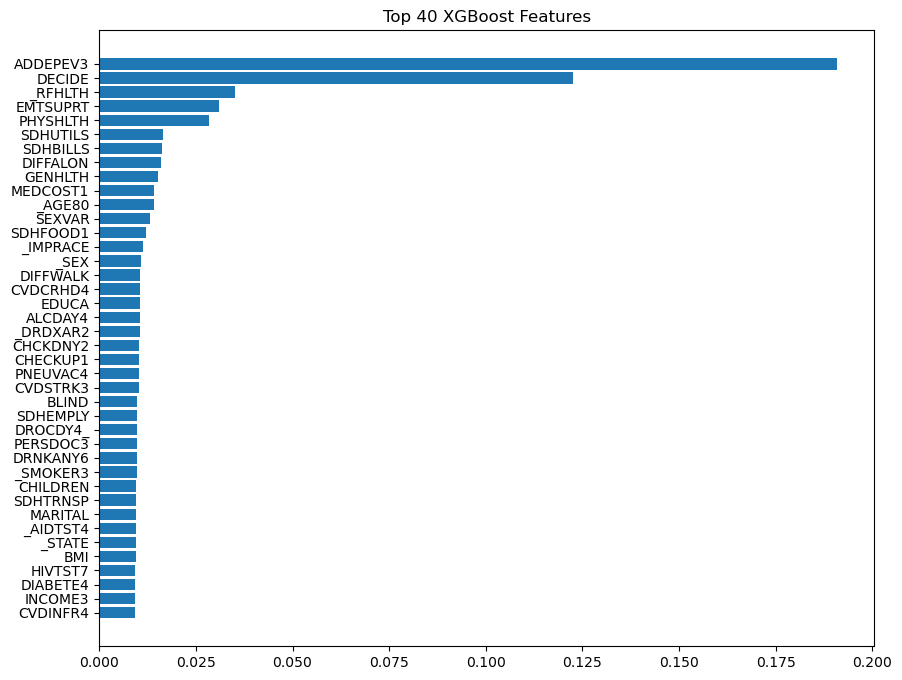

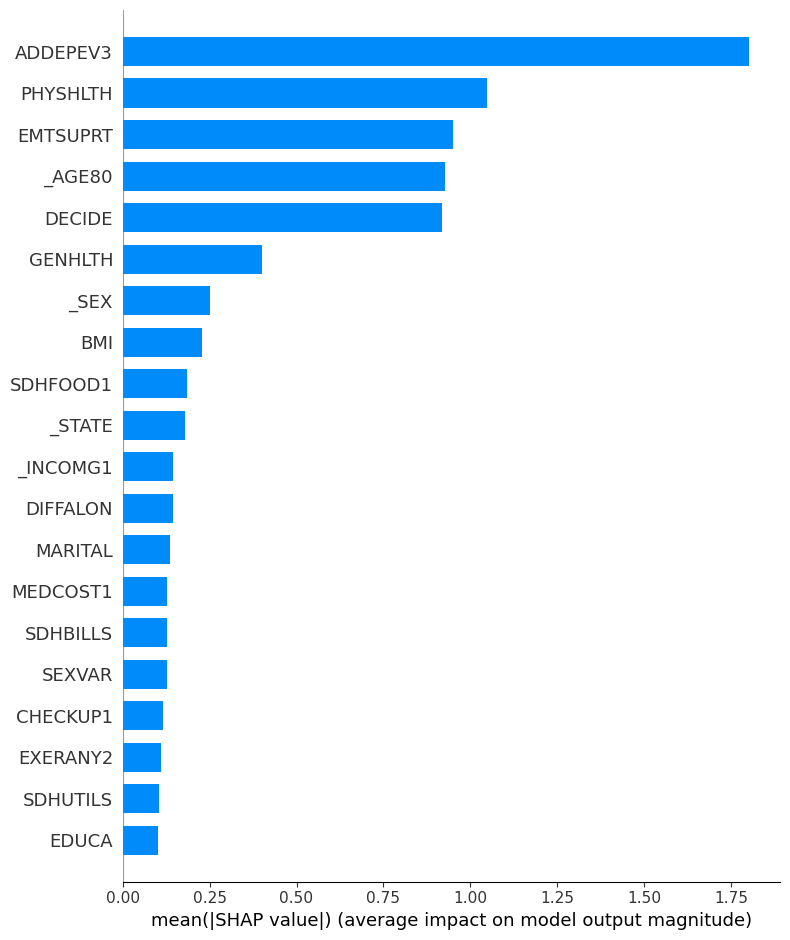

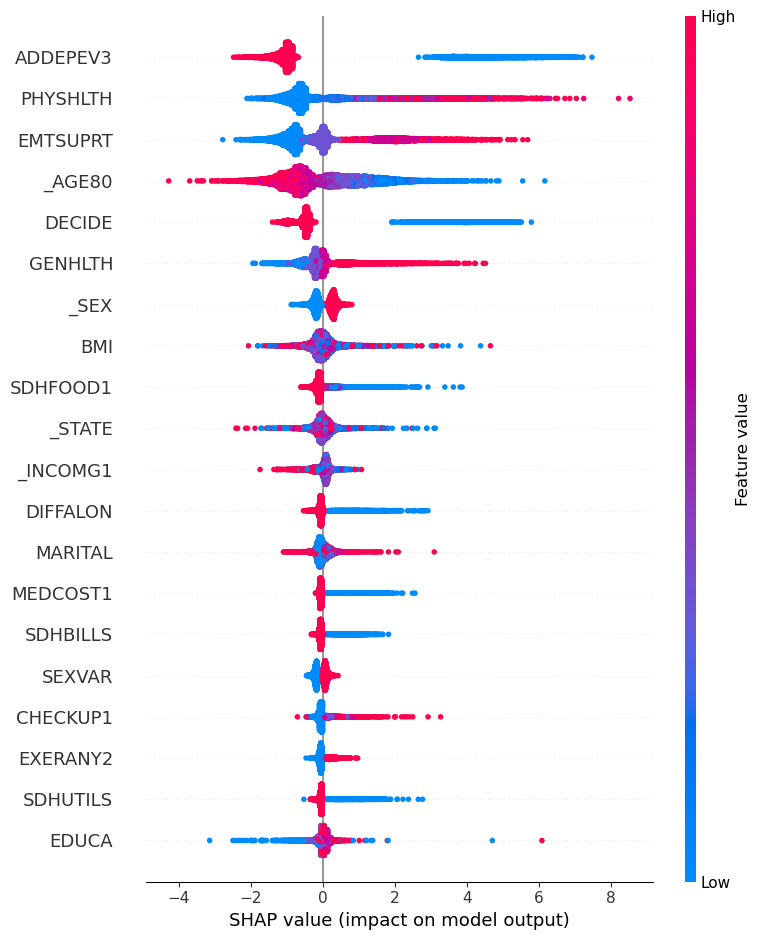


Saved: BRFSS_40-feature_importance_target-MENTHLTH.csv

     feature  shap_importance
58  ADDEPEV3         1.800869
55  PHYSHLTH         1.047685
45  EMTSUPRT         0.950847
10    _AGE80         0.928174
34    DECIDE         0.919230
23   GENHLTH         0.399259
16      _SEX         0.250126
67       BMI         0.228958
50  SDHFOOD1         0.185878
42    _STATE         0.179197
3   _INCOMG1         0.145606
4   DIFFALON         0.145323
15   MARITAL         0.134763
37  MEDCOST1         0.128595
54  SDHBILLS         0.128008
28    SEXVAR         0.126856
21  CHECKUP1         0.114593
12  EXERANY2         0.111539
33  SDHUTILS         0.104754
46     EDUCA         0.102828
35   ALCDAY4         0.102023
24   INCOME3         0.101695
41  _SMOKER3         0.097246
18  _METSTAT         0.097090
63  _IMPRACE         0.092911
47  DIFFWALK         0.090539
64   _RFHLTH         0.088968
6    HHADULT         0.086683
27  SDHEMPLY         0.085110
8   _AIDTST4         0.084270
30  DROCDY4_ 

In [39]:
# ============================================================
# BRFSS Feature Importance using XGBoost
# Target: MENTHLTH
# ============================================================

print(f"Feature importance for target {target}")

# ============================================================
# Train Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ============================================================
# Train XGBoost
# ============================================================

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

# ============================================================
# Evaluate
# ============================================================

preds = model.predict(
    X_test
)

print()
print("MAE :", mean_absolute_error(y_test, preds))
print("R2  :", r2_score(y_test, preds))

# ============================================================
# XGBoost Native Importance
# ============================================================

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print()
print(f"Top {n_important_features} Features")
print(
    importance.head(n_important_features)
)

# ============================================================
# Plot Top Features
# ============================================================

top = importance.head(n_important_features)

plt.figure(figsize=(10,8))

plt.barh(
    top["feature"],
    top["importance"]
)

plt.gca().invert_yaxis()

plt.title(
    f"Top {n_important_features} XGBoost Features"
)

plt.show()

# ============================================================
# SHAP Explainability
# ============================================================

explainer = shap.TreeExplainer(
    model
)

# use sample for speed

sample = X_train.sample(
    min(10000, len(X_train)),
    random_state=42
)

shap_values = explainer.shap_values(
    sample
)

# ============================================================
# SHAP Global Importance
# ============================================================

shap.summary_plot(
    shap_values,
    sample,
    plot_type="bar"
)

# ============================================================
# SHAP Detailed Summary
# ============================================================

shap.summary_plot(
    shap_values,
    sample
)

# ============================================================
# Save Ranked Features
# ============================================================

shap_importance = pd.DataFrame({

    "feature": sample.columns,

    "shap_importance":
        np.abs(shap_values).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "shap_importance",
    ascending=False
)

shap_importance.to_csv(
    f"BRFSS_{n_important_features}-feature_importance_target-{target}.csv",
    index=False
)

print()
print(f"Saved: BRFSS_{n_important_features}-feature_importance_target-{target}.csv")

print()
print(shap_importance.head(n_important_features))

In [40]:
xgb_important_feature_names = list(importance.feature[:n_important_features])
print("XGBoost")
for i, feature_name in enumerate(xgb_important_feature_names, 1):
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

XGBoost
1 	 ADDEPEV3 	 (ever told) you had a depressive disorder
2 	 DECIDE 	 Difficulty concentrating or remembering
3 	 _RFHLTH 	 Adults with good or better health
4 	 EMTSUPRT 	 How often get emotional support needed
5 	 PHYSHLTH 	 Number of days physical health not good
6 	 SDHUTILS 	 Were you not able to pay utility bills or threatened to lose service?
7 	 SDHBILLS 	 Were you not able to pay your bills?
8 	 DIFFALON 	 Difficulty doing errands alone
9 	 GENHLTH 	 General health
10 	 MEDCOST1 	 Could not afford to see doctor
11 	 _AGE80 	 Imputed age value collapsed above 80
12 	 SEXVAR 	 Sex of respondent
13 	 SDHFOOD1 	 How often did the food that you bought not last, and you didnt have money to get more?
14 	 _IMPRACE 	 Imputed race/ethnicity value
15 	 _SEX 	 Calculated sex variable
16 	 DIFFWALK 	 Difficulty walking or climbing stairs
17 	 CVDCRHD4 	 Ever diagnosed with angina or coronary heart disease
18 	 EDUCA 	 Education level
19 	 ALCDAY4 	 Days in past 30 had alcoholic b

In [41]:
shap_important_feature_names = list(shap_importance.feature[:n_important_features])
print("SHAP")
for i, feature_name in enumerate(shap_important_feature_names, 1):
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

SHAP
1 	 ADDEPEV3 	 (ever told) you had a depressive disorder
2 	 PHYSHLTH 	 Number of days physical health not good
3 	 EMTSUPRT 	 How often get emotional support needed
4 	 _AGE80 	 Imputed age value collapsed above 80
5 	 DECIDE 	 Difficulty concentrating or remembering
6 	 GENHLTH 	 General health
7 	 _SEX 	 Calculated sex variable
8 	 BMI 	 Body mass index
9 	 SDHFOOD1 	 How often did the food that you bought not last, and you didnt have money to get more?
10 	 _STATE 	 State fips code
11 	 _INCOMG1 	 Computed income categories
12 	 DIFFALON 	 Difficulty doing errands alone
13 	 MARITAL 	 Marital status
14 	 MEDCOST1 	 Could not afford to see doctor
15 	 SDHBILLS 	 Were you not able to pay your bills?
16 	 SEXVAR 	 Sex of respondent
17 	 CHECKUP1 	 Length of time since last routine checkup
18 	 EXERANY2 	 Exercise in past 30 days
19 	 SDHUTILS 	 Were you not able to pay utility bills or threatened to lose service?
20 	 EDUCA 	 Education level
21 	 ALCDAY4 	 Days in past 30 had al

In [42]:
len(set(shap_important_feature_names).intersection(set(xgb_important_feature_names)))

32

In [43]:
set(shap_important_feature_names).difference(set(xgb_important_feature_names))

{'EMPLOY1',
 'EXERANY2',
 'HHADULT',
 'RENTHOM1',
 '_ASTHMS1',
 '_HISPANC',
 '_INCOMG1',
 '_METSTAT'}

In [44]:
set(xgb_important_feature_names).difference(set(shap_important_feature_names))

{'BLIND',
 'CHCKDNY2',
 'CVDCRHD4',
 'CVDINFR4',
 'CVDSTRK3',
 'DRNKANY6',
 'HIVTST7',
 '_DRDXAR2'}

In [45]:
for shap_important_feature_name in xgb_important_feature_names:
    print(shap_important_feature_name, ":", feature_details[shap_important_feature_name]["desc"])

ADDEPEV3 : (ever told) you had a depressive disorder
DECIDE : Difficulty concentrating or remembering
_RFHLTH : Adults with good or better health
EMTSUPRT : How often get emotional support needed
PHYSHLTH : Number of days physical health not good
SDHUTILS : Were you not able to pay utility bills or threatened to lose service?
SDHBILLS : Were you not able to pay your bills?
DIFFALON : Difficulty doing errands alone
GENHLTH : General health
MEDCOST1 : Could not afford to see doctor
_AGE80 : Imputed age value collapsed above 80
SEXVAR : Sex of respondent
SDHFOOD1 : How often did the food that you bought not last, and you didnt have money to get more?
_IMPRACE : Imputed race/ethnicity value
_SEX : Calculated sex variable
DIFFWALK : Difficulty walking or climbing stairs
CVDCRHD4 : Ever diagnosed with angina or coronary heart disease
EDUCA : Education level
ALCDAY4 : Days in past 30 had alcoholic beverage
_DRDXAR2 : Respondents diagnosed with arthritis
CHCKDNY2 : Ever told you have kidney d

In [46]:
for shap_important_feature_name in shap_important_feature_names:
    print(shap_important_feature_name, ":", feature_details[shap_important_feature_name]["desc"])

ADDEPEV3 : (ever told) you had a depressive disorder
PHYSHLTH : Number of days physical health not good
EMTSUPRT : How often get emotional support needed
_AGE80 : Imputed age value collapsed above 80
DECIDE : Difficulty concentrating or remembering
GENHLTH : General health
_SEX : Calculated sex variable
BMI : Body mass index
SDHFOOD1 : How often did the food that you bought not last, and you didnt have money to get more?
_STATE : State fips code
_INCOMG1 : Computed income categories
DIFFALON : Difficulty doing errands alone
MARITAL : Marital status
MEDCOST1 : Could not afford to see doctor
SDHBILLS : Were you not able to pay your bills?
SEXVAR : Sex of respondent
CHECKUP1 : Length of time since last routine checkup
EXERANY2 : Exercise in past 30 days
SDHUTILS : Were you not able to pay utility bills or threatened to lose service?
EDUCA : Education level
ALCDAY4 : Days in past 30 had alcoholic beverage
INCOME3 : Income level
_SMOKER3 : Computed smoking status
_METSTAT : Metropolitan st

In [47]:
df_combined = pd.concat([X, y], axis=1)

# Save preprocessed data with important features
df_preprocessed_with_feature_importance = df_combined.loc[:, shap_important_feature_names + [target]]
df_preprocessed_with_feature_importance.to_csv(
                    f"data/preprocessed/{n_years}-years_{len(df_preprocessed_with_feature_importance)}-samples_{n_important_features}-features_{target}-target.csv",
                    index=False
)

## LSATISFY

---

# Data Visualization

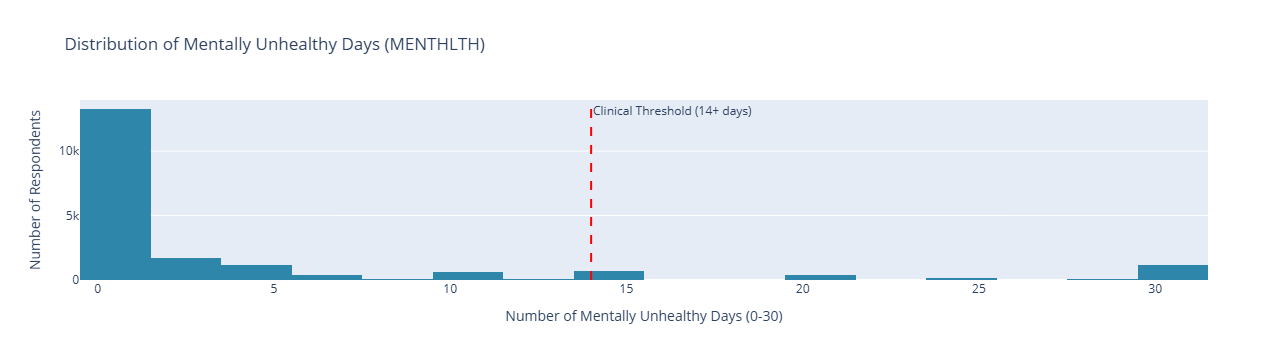

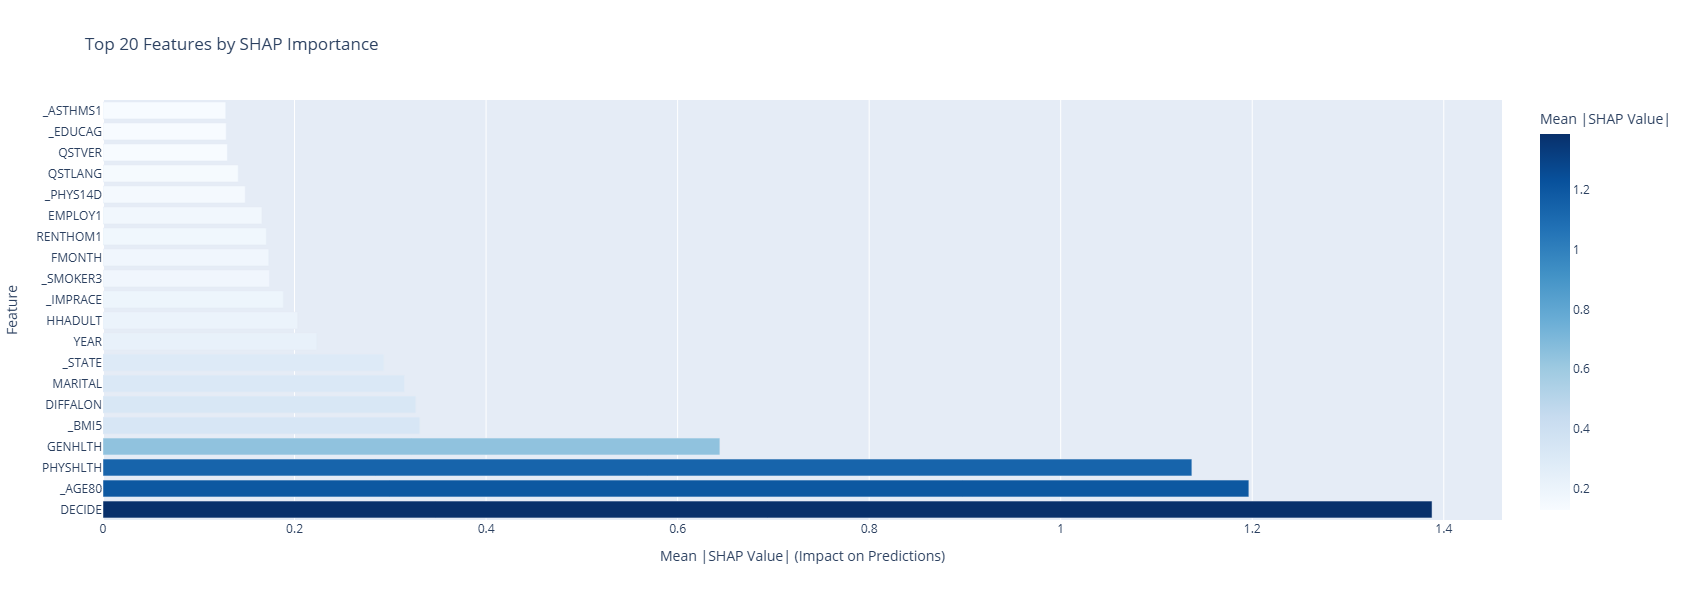

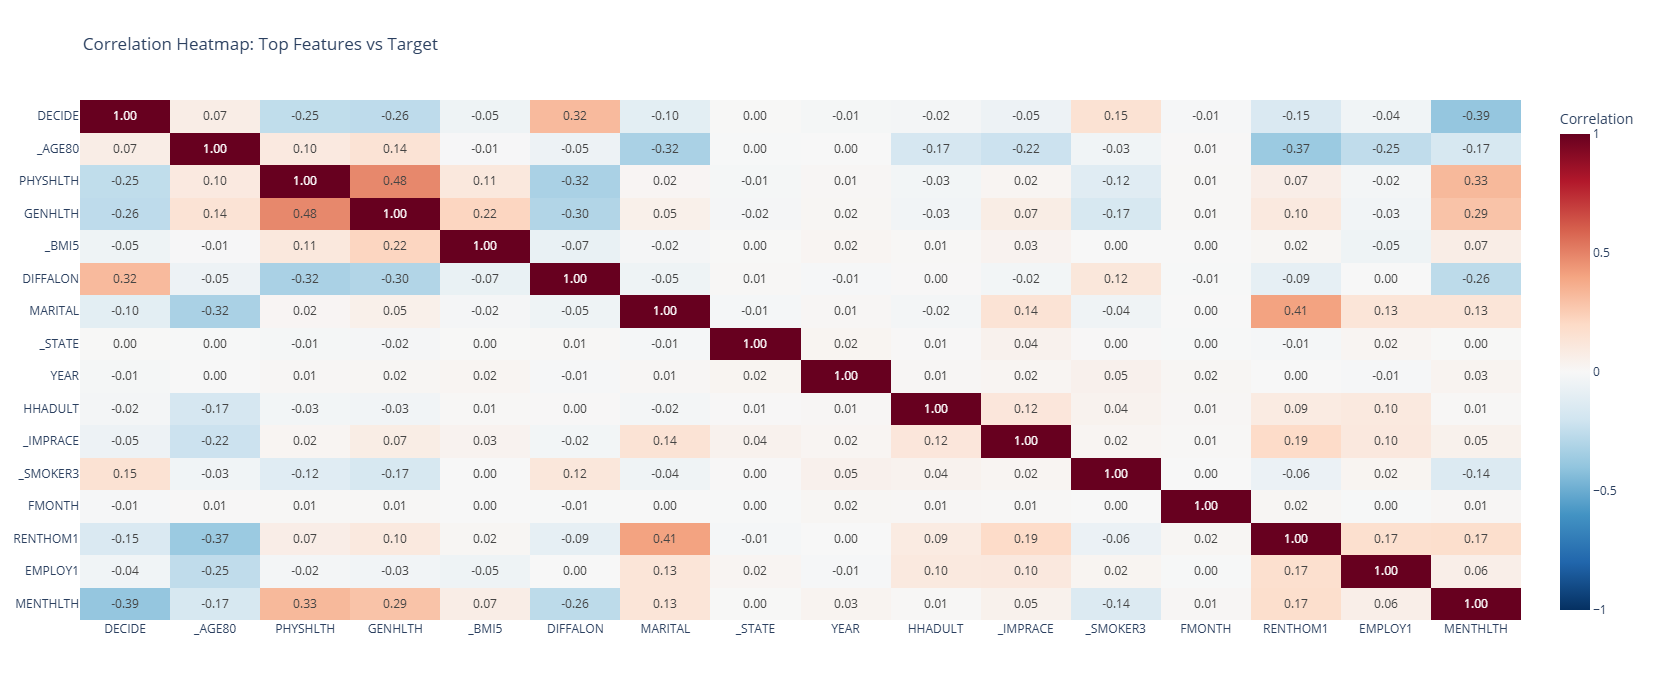

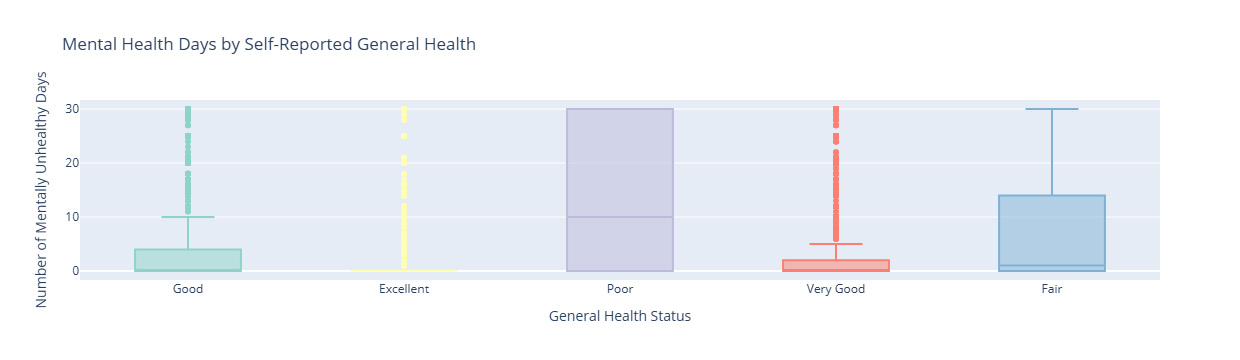

In [ ]:
# Create plots directory if it doesn't exist
os.makedirs("plots", exist_ok=True)

# ============================================================
# 1. Target Distribution (MENTHLTH)
# ============================================================
fig1 = px.histogram(
    y,
    nbins=30,
    title="Distribution of Mentally Unhealthy Days (MENTHLTH)",
    labels={"value": "Number of Days", "count": "Frequency"},
    color_discrete_sequence=["#2E86AB"]
)
fig1.add_vline(x=14, line_dash="dash", line_color="red", 
               annotation_text="Clinical Threshold (14+ days)")
fig1.update_layout(
    xaxis_title="Number of Mentally Unhealthy Days (0-30)",
    yaxis_title="Number of Respondents",
    showlegend=False
)
fig1.write_html("plots/1_target_distribution.html")
fig1.show()

# ============================================================
# 2. Top 20 SHAP Features - Waterfall Summary
# ============================================================
fig2 = px.bar(
    shap_importance.head(20),
    x="shap_importance",
    y="feature",
    orientation='h',
    title="Top 20 Features by SHAP Importance",
    labels={"shap_importance": "Mean |SHAP Value|", "feature": ""},
    color="shap_importance",
    color_continuous_scale="Blues"
)
fig2.update_layout(
    xaxis_title="Mean |SHAP Value| (Impact on Predictions)",
    yaxis_title="Feature",
    height=600,
    showlegend=False
)
fig2.write_html("plots/2_top_shap_features.html")
fig2.show()

# ============================================================
# 3. Correlation Heatmap of Top Features
# ============================================================
top_features = shap_importance.head(15)["feature"].tolist()
corr_data = X[top_features].copy()
corr_data[target] = y.values  # if y is separate
corr_matrix = corr_data.corr()

fig3 = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title="Correlation Heatmap: Top Features vs Target",
    labels={"color": "Correlation", "variable": "", "y": ""},
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)
fig3.update_layout(
    height=700,
    width=800
)
fig3.write_html("plots/3_correlation_heatmap.html")
fig3.show()

# ============================================================
# 4. Scatter: ADDEPEV3 (Depression) vs MENTHLTH
# ============================================================
if "ADDEPEV3" in X:
    fig4 = px.box(
        pd.DataFrame({target: y, "ADDEPEV3": X["ADDEPEV3"]}),
        x="ADDEPEV3",
        y=target,
        color="ADDEPEV3",
        title="Mental Health Days by Depressive Disorder Diagnosis",
        labels={"ADDEPEV3": "Ever Told Depressive Disorder", target: "Mentally Unhealthy Days"},
        color_discrete_sequence=px.colors.qualitative.Set2
    )
    fig4.update_layout(
        xaxis_title="Ever Told Depressive Disorder (1=Yes, 2=No)",
        yaxis_title="Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig4.write_html("plots/4_depression_vs_menthealth.html")
    fig4.show()

# ============================================================
# 5. Scatter: GENHLTH (General Health) vs MENTHLTH
# ============================================================
genhlth_labels = {1: "Excellent", 2: "Very Good", 3: "Good", 4: "Fair", 5: "Poor"}
df_plot = pd.DataFrame({
    target: y,
    "GENHLTH": X["GENHLTH"]
})
df_plot["GENHLTH_LABEL"] = df_plot["GENHLTH"].map(genhlth_labels)

fig5 = px.box(
    df_plot,
    x="GENHLTH_LABEL",
    y=target,
    title="Mental Health Days by Self-Reported General Health",
    labels={"GENHLTH_LABEL": "General Health Status", target: "Mentally Unhealthy Days"},
    color="GENHLTH_LABEL",
    color_discrete_sequence=px.colors.qualitative.Set3
)
fig5.update_layout(
    xaxis_title="General Health Status",
    yaxis_title="Number of Mentally Unhealthy Days",
    showlegend=False
)
fig5.write_html("plots/5_genhlth_vs_menthealth.html")
fig5.show()

# ============================================================
# 6. PHYSHLTH vs MENTHLTH Scatter
# ============================================================
df_scatter = pd.DataFrame({
    target: y,
    "PHYSHLTH": X["PHYSHLTH"]
})
# Sample for performance
df_scatter_sample = df_scatter.sample(min(10000, len(df_scatter)), random_state=42)

fig6 = px.scatter(
    df_scatter_sample,
    x="PHYSHLTH",
    y=target,
    title="Physical Health Days vs Mental Health Days",
    labels={"PHYSHLTH": "Days Physical Health Not Good", target: "Days Mental Health Not Good"},
    opacity=0.5,
    trendline="ols",
    color_discrete_sequence=["#2E86AB"]
)
fig6.update_layout(
    xaxis_title="Days Physical Health Not Good (0-30)",
    yaxis_title="Days Mental Health Not Good (0-30)"
)
fig6.write_html("plots/6_physhlth_vs_menthlth.html")
fig6.show()

# ============================================================
# 7. Age Distribution of Mental Health Days
# ============================================================
age_labels = {
    1: "18-24", 2: "25-34", 3: "35-44", 
    4: "45-54", 5: "55-64", 6: "65+"
}
df_age = pd.DataFrame({
    target: y,
    "AGE_G": X["_AGE_G"]
})
df_age["AGE_GROUP"] = df_age["AGE_G"].map(age_labels)

fig7 = px.box(
    df_age,
    x="AGE_GROUP",
    y=target,
    title="Mental Health Days by Age Group",
    labels={"AGE_GROUP": "Age Group", target: "Mentally Unhealthy Days"},
    color="AGE_GROUP",
    color_discrete_sequence=px.colors.qualitative.Set1
)
fig7.update_layout(
    xaxis_title="Age Group",
    yaxis_title="Number of Mentally Unhealthy Days",
    showlegend=False
)
fig7.write_html("plots/7_age_vs_menthealth.html")
fig7.show()

# ============================================================
# 8. Sex Comparison of Mental Health Days
# ============================================================
if "SEX" in X:
    sex_labels = {1: "Male", 2: "Female"}
    df_sex = pd.DataFrame({
        target: y,
        "SEX": X["_SEX"]
    })
    df_sex["SEX_LABEL"] = df_sex["SEX"].map(sex_labels)
    
    fig8 = px.box(
        df_sex,
        x="SEX_LABEL",
        y=target,
        title="Mental Health Days by Sex",
        labels={"SEX_LABEL": "Sex", target: "Mentally Unhealthy Days"},
        color="SEX_LABEL",
        color_discrete_sequence=["#1F77B4", "#FF7F0E"]
    )
    fig8.update_layout(
        xaxis_title="Sex",
        yaxis_title="Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig8.write_html("plots/8_sex_vs_menthealth.html")
    fig8.show()

# ============================================================
# 9. DECIDE (Cognitive Difficulty) vs MENTHLTH
# ============================================================
decide_labels = {1: "Yes", 2: "No"}
df_decide = pd.DataFrame({
    target: y,
    "DECIDE": X["DECIDE"]
})
df_decide["DECIDE_LABEL"] = df_decide["DECIDE"].map(decide_labels)

fig9 = px.box(
    df_decide,
    x="DECIDE_LABEL",
    y=target,
    title="Mental Health Days by Cognitive Difficulty",
    labels={"DECIDE_LABEL": "Difficulty Concentrating or Remembering", target: "Mentally Unhealthy Days"},
    color="DECIDE_LABEL",
    color_discrete_sequence=["#D62728", "#2CA02C"]
)
fig9.update_layout(
    xaxis_title="Difficulty Concentrating or Remembering",
    yaxis_title="Number of Mentally Unhealthy Days",
    showlegend=False
)
fig9.write_html("plots/9_decide_vs_menthealth.html")
fig9.show()

# ============================================================
# 10. State-wise Mental Health Days (Geographic Analysis)
# ============================================================
if "_STATE" in X.columns:
    state_labels = {1: "AL", 2: "AK", 4: "AZ", 5: "AR", 6: "CA", 8: "CO", 
                    9: "CT", 10: "DE", 11: "DC", 12: "FL", 13: "GA", 15: "HI",
                    16: "ID", 17: "IL", 18: "IN", 19: "IA", 20: "KS", 21: "KY",
                    22: "LA", 23: "ME", 24: "MD", 25: "MA", 26: "MI", 27: "MN",
                    28: "MS", 29: "MO", 30: "MT", 31: "NE", 32: "NV", 33: "NH",
                    34: "NJ", 35: "NM", 36: "NY", 37: "NC", 38: "ND", 39: "OH",
                    40: "OK", 41: "OR", 42: "PA", 44: "RI", 45: "SC", 46: "SD",
                    47: "TN", 48: "TX", 49: "UT", 50: "VT", 51: "VA", 53: "WA",
                    54: "WV", 55: "WI", 56: "WY", 66: "GU", 72: "PR", 78: "VI"}
    
    df_state = pd.DataFrame({
        target: y,
        "_STATE": X["_STATE"]
    })
    df_state["STATE_ABBR"] = df_state["_STATE"].map(state_labels)
    
    # Calculate mean mental health days by state
    state_means = df_state.groupby("STATE_ABBR")[target].mean().sort_values().reset_index()
    
    fig10 = px.bar(
        state_means,
        x="STATE_ABBR",
        y=target,
        title="Average Mental Health Days by State",
        labels={"STATE_ABBR": "State", target: "Mean Mentally Unhealthy Days"},
        color=target,
        color_continuous_scale="Reds"
    )
    fig10.update_layout(
        xaxis_title="State",
        yaxis_title="Mean Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig10.write_html("plots/10_state_vs_menthealth.html")
    fig10.show()

# ============================================================
# 11. MEDCOST1 (Affordability) vs MENTHLTH
# ============================================================
if "MEDCOST1" in X.columns:
    medcost_labels = {1: "Yes", 2: "No"}
    df_medcost = pd.DataFrame({
        target: y,
        "MEDCOST1": X[""]
    })
    df_medcost["MEDCOST_LABEL"] = df_medcost["MEDCOST1"].map(medcost_labels)
    
    fig11 = px.box(
        df_medcost,
        x="MEDCOST_LABEL",
        y=target,
        title="Mental Health Days by Ability to Afford Doctor",
        labels={"MEDCOST_LABEL": "Could Not Afford to See Doctor", target: "Mentally Unhealthy Days"},
        color="MEDCOST_LABEL",
        color_discrete_sequence=["#9467BD", "#8C564B"]
    )
    fig11.update_layout(
        xaxis_title="Could Not Afford to See Doctor (1=Yes, 2=No)",
        yaxis_title="Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig11.write_html("plots/11_medcost_vs_menthealth.html")
    fig11.show()

# ============================================================
# 12. Interactive Dashboard: Top Feature Relationships
# ============================================================
if "ADDEPEV3" in X.columns and "DECIDE" in X.columns:
    # Create a 2x2 subplot dashboard
    fig12 = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            "ADDEPEV3 (Depression) vs MENTHLTH",
            "DECIDE (Cognitive) vs MENTHLTH",
            "PHYSHLTH vs MENTHLTH",
            "GENHLTH vs MENTHLTH"
        )
    )
    
    # Plot 1: ADDEPEV3
    fig12.add_trace(
        go.Box(y=y, x=X["ADDEPEV3"], name="ADDEPEV3", showlegend=False),
        row=1, col=1
    )
    
    # Plot 2: DECIDE
    fig12.add_trace(
        go.Box(y=y, x=X["DECIDE"], name="DECIDE", showlegend=False),
        row=1, col=2
    )
    
    # Plot 3: PHYSHLTH (scatter, sampled)
    sample_idx = np.random.choice(len(X), min(5000, len(X)), replace=False)
    fig12.add_trace(
        go.Scatter(
            x=X["PHYSHLTH"].iloc[sample_idx],
            y=y.iloc[sample_idx],
            mode="markers",
            marker=dict(size=3, opacity=0.5),
            name="PHYSHLTH",
            showlegend=False
        ),
        row=2, col=1
    )
    
    # Plot 4: GENHLTH
    fig12.add_trace(
        go.Box(y=y, x=X["GENHLTH"], name="GENHLTH", showlegend=False),
        row=2, col=2
    )
    
    fig12.update_layout(
        height=800,
        width=1000,
        title_text="Interactive Dashboard: Key Features vs Mental Health Days",
        showlegend=False
    )
    
    fig12.update_xaxes(title_text="ADDEPEV3", row=1, col=1)
    fig12.update_xaxes(title_text="DECIDE", row=1, col=2)
    fig12.update_xaxes(title_text="PHYSHLTH", row=2, col=1)
    fig12.update_xaxes(title_text="GENHLTH", row=2, col=2)
    
    fig12.update_yaxes(title_text="MENTHLTH", row=1, col=1)
    fig12.update_yaxes(title_text="MENTHLTH", row=1, col=2)
    fig12.update_yaxes(title_text="MENTHLTH", row=2, col=1)
    fig12.update_yaxes(title_text="MENTHLTH", row=2, col=2)
    
    fig12.write_html("plots/12_dashboard_key_features.html")
    fig12.show()

# ============================================================
# 13. Scatter: DECIDE vs MENTHLTH
# ============================================================
if "DECIDE" in X:
    fig13 = px.box(
        pd.DataFrame({target: y, "DECIDE": X["DECIDE"]}),
        x="DECIDE",
        y=target,
        color="DECIDE",
        title="Mental Health Days by Decide",
        labels={"DECIDE": "Difficulty Concentrating Or Remembering", target: "Mentally Unhealthy Days"},
        color_discrete_sequence=px.colors.qualitative.Set2
    )
    fig13.update_layout(
        xaxis_title="Difficulty Concentrating Or Remembering (1=Yes, 2=No)",
        yaxis_title="Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig13.write_html("plots/13_decide_vs_menthealth.html")
    fig13.show()

    
print("All plots saved to /plots directory!")

---